**SOCIAL MEDIA USAGE ANALYSIS**


Name: ARYA SINGH


Class: B3[B1]


R.No.: 02

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from scipy import stats
np.random.seed(42)

**Web Scraping / Data Collection**

In [ ]:
import pandas as pd

url = "https://gist.githubusercontent.com/ontipulikesava153/00de7c8bbf6846daef91955970c06e92/raw/social_media_usage.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)

  User_ID        App  Daily_Minutes_Spent  Posts_Per_Day  Likes_Per_Day  \
0     U_1  Pinterest                  288             16             94   
1     U_2   Facebook                  192             14            117   
2     U_3  Instagram                  351             13            120   
3     U_4     TikTok                   21             20            117   
4     U_5   LinkedIn                  241             16              9   

   Follows_Per_Day  
0                0  
1               15  
2               48  
3                8  
4               21  
(1000, 6)


In [ ]:
import requests
from bs4 import BeautifulSoup
response = requests.get(url)

print("Status Code:", response.status_code)
print(response.text[:500])

Status Code: 200
User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
U_1,Pinterest,288,16,94,0
U_2,Facebook,192,14,117,15
U_3,Instagram,351,13,120,48
U_4,TikTok,21,20,117,8
U_5,LinkedIn,241,16,9,21
U_6,Twitter,464,3,137,30
U_7,LinkedIn,229,1,188,25
U_8,LinkedIn,8,19,179,48
U_9,TikTok,80,7,14,25
U_10,Snapchat,428,6,4,41
U_11,Snapchat,52,18,124,26
U_12,Facebook,314,18,132,28
U_13,LinkedIn,26,17,198,18
U_14,Instagram,427,0,110,19
U_15,Facebook,434,2,111,16
U_16,Twitter,494,10,93,49
U_17,Snap


In [ ]:
soup = BeautifulSoup(response.text, "html.parser")

print("HTML/Text Data:")
print(soup.get_text()[:500])

HTML/Text Data:
User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
U_1,Pinterest,288,16,94,0
U_2,Facebook,192,14,117,15
U_3,Instagram,351,13,120,48
U_4,TikTok,21,20,117,8
U_5,LinkedIn,241,16,9,21
U_6,Twitter,464,3,137,30
U_7,LinkedIn,229,1,188,25
U_8,LinkedIn,8,19,179,48
U_9,TikTok,80,7,14,25
U_10,Snapchat,428,6,4,41
U_11,Snapchat,52,18,124,26
U_12,Facebook,314,18,132,28
U_13,LinkedIn,26,17,198,18
U_14,Instagram,427,0,110,19
U_15,Facebook,434,2,111,16
U_16,Twitter,494,10,93,49
U_17,Snap


In [ ]:
from io import StringIO
df = pd.read_csv(StringIO(response.text))

print("Table Data:")
display(df.head())

Table Data:


,User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
0,U_1,Pinterest,288,16,94,0
1,U_2,Facebook,192,14,117,15
2,U_3,Instagram,351,13,120,48
3,U_4,TikTok,21,20,117,8
4,U_5,LinkedIn,241,16,9,21


In [ ]:
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Shape: (1000, 6)
Columns:
['User_ID', 'App', 'Daily_Minutes_Spent', 'Posts_Per_Day', 'Likes_Per_Day', 'Follows_Per_Day']


**Data Cleaning & Preprocessing**

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
User_ID                0
App                    0
Daily_Minutes_Spent    0
Posts_Per_Day          0
Likes_Per_Day          0
Follows_Per_Day        0
dtype: int64


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
df = df.drop_duplicates()
df = df.dropna()

print("After Cleaning:", df.shape)

After Cleaning: (1000, 6)


In [ ]:
print(df.dtypes)

User_ID                object
App                    object
Daily_Minutes_Spent     int64
Posts_Per_Day           int64
Likes_Per_Day           int64
Follows_Per_Day         int64
dtype: object


**Descriptive Statistics**

In [ ]:
print(df.columns.tolist())

['User_ID', 'App', 'Daily_Minutes_Spent', 'Posts_Per_Day', 'Likes_Per_Day', 'Follows_Per_Day']


In [ ]:
usage = df["Daily_Minutes_Spent"]

print("Mean:", usage.mean())
print("Median:", usage.median())
print("Mode:", usage.mode()[0])
print("Minimum:", usage.min())
print("Maximum:", usage.max())
print("Range:", usage.max() - usage.min())

Mean: 247.368
Median: 246.0
Mode: 76
Minimum: 5
Maximum: 500
Range: 495


In [ ]:
print("Variance:", usage.var())
print("Standard Deviation:", usage.std())

Variance: 21424.73931531536
Standard Deviation: 146.3719211984162


In [ ]:
print(df.describe())

       Daily_Minutes_Spent  Posts_Per_Day  Likes_Per_Day  Follows_Per_Day
count          1000.000000    1000.000000    1000.000000      1000.000000
mean            247.368000      10.269000      94.682000        24.698000
std             146.371921       6.121774      57.560943        14.842948
min               5.000000       0.000000       0.000000         0.000000
25%             112.750000       5.000000      44.750000        12.000000
50%             246.000000      10.000000      94.000000        24.000000
75%             380.500000      16.000000     142.000000        38.000000
max             500.000000      20.000000     200.000000        50.000000


**Data Visualization**

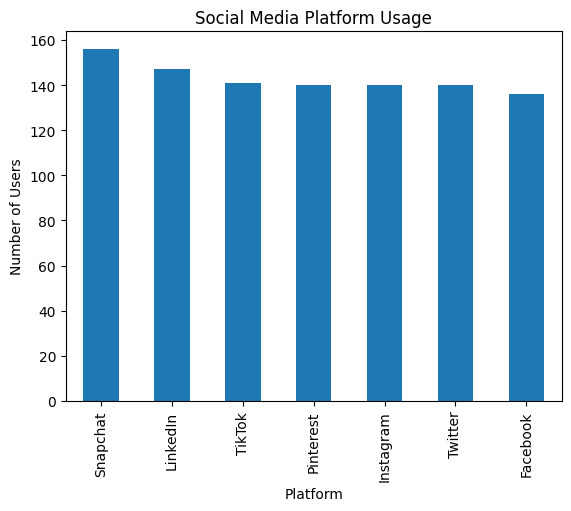

In [ ]:
import matplotlib.pyplot as plt

df["App"].value_counts().plot(kind="bar")

plt.title("Social Media Platform Usage")
plt.xlabel("Platform")
plt.ylabel("Number of Users")
plt.show()

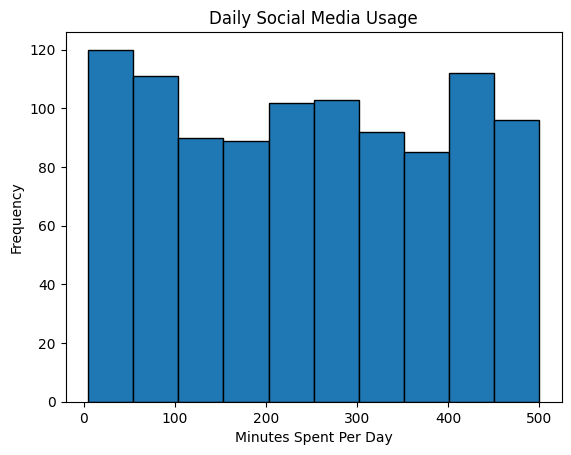

In [ ]:
plt.hist(
    df["Daily_Minutes_Spent"],
    bins=10,
    edgecolor="black"
)

plt.title("Daily Social Media Usage")
plt.xlabel("Minutes Spent Per Day")
plt.ylabel("Frequency")
plt.show()

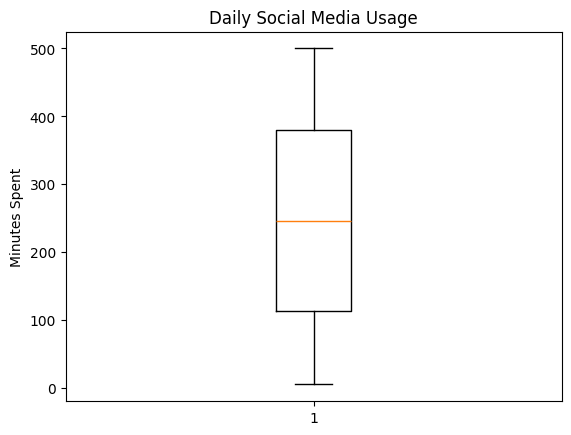

In [ ]:
plt.boxplot(df["Daily_Minutes_Spent"])

plt.title("Daily Social Media Usage")
plt.ylabel("Minutes Spent")
plt.show()

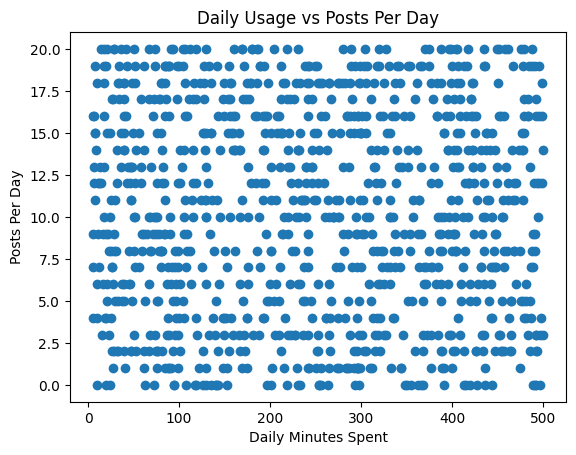

In [ ]:
plt.scatter(
    df["Daily_Minutes_Spent"],
    df["Posts_Per_Day"]
)

plt.title("Daily Usage vs Posts Per Day")
plt.xlabel("Daily Minutes Spent")
plt.ylabel("Posts Per Day")
plt.show()

**Uniform Distribution**

In [ ]:
minimum = df["Daily_Minutes_Spent"].min()
maximum = df["Daily_Minutes_Spent"].max()

uniform_data = np.random.uniform(
    minimum,
    maximum,
    1000
)

print("Minimum:", minimum)
print("Maximum:", maximum)
print("Uniform Mean:", uniform_data.mean())

Minimum: 5
Maximum: 500
Uniform Mean: 247.67699389346615


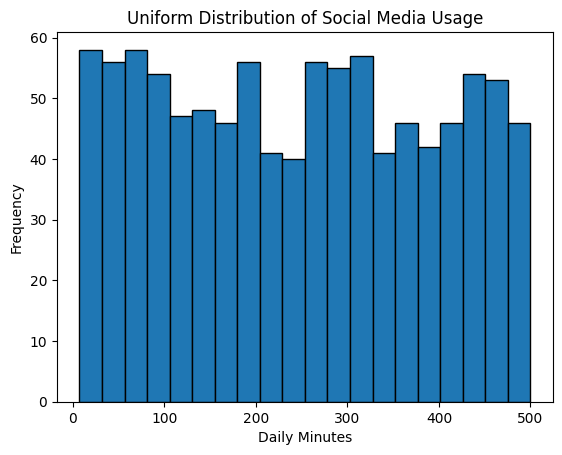

In [ ]:
plt.hist(
    uniform_data,
    bins=20,
    edgecolor="black"
)

plt.title("Uniform Distribution of Social Media Usage")
plt.xlabel("Daily Minutes")
plt.ylabel("Frequency")
plt.show()

**Normal Distribution**

In [ ]:
mean = df["Daily_Minutes_Spent"].mean()
std = df["Daily_Minutes_Spent"].std()

normal_data = np.random.normal(
    mean,
    std,
    1000
)

print("Mean:", mean)
print("Standard Deviation:", std)
print("Generated Mean:", normal_data.mean())

Mean: 247.368
Standard Deviation: 146.3719211984162
Generated Mean: 261.84357087160964


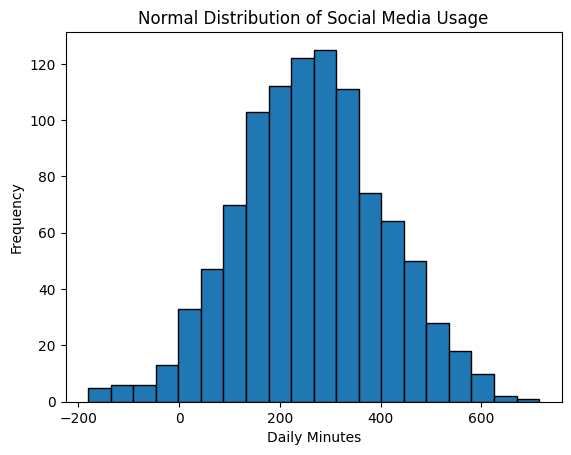

In [ ]:
plt.hist(
    normal_data,
    bins=20,
    edgecolor="black"
)

plt.title("Normal Distribution of Social Media Usage")
plt.xlabel("Daily Minutes")
plt.ylabel("Frequency")
plt.show()

**Poisson Distribution**

In [ ]:
lambda_value = df["Posts_Per_Day"].mean()

poisson_data = np.random.poisson(
    lambda_value,
    1000
)

print("Average Posts Per Day:", lambda_value)
print("Generated Mean:", poisson_data.mean())

Average Posts Per Day: 10.269
Generated Mean: 10.18


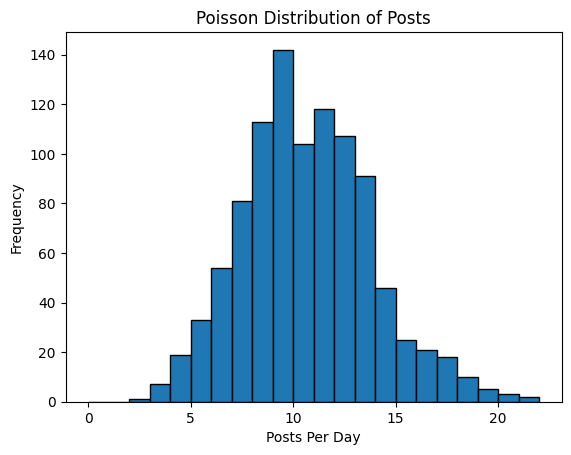

In [ ]:
plt.hist(
    poisson_data,
    bins=range(int(poisson_data.max()) + 2),
    edgecolor="black"
)

plt.title("Poisson Distribution of Posts")
plt.xlabel("Posts Per Day")
plt.ylabel("Frequency")
plt.show()

**Binomial Distribution**

In [ ]:
median_usage = df["Daily_Minutes_Spent"].median()

p = (df["Daily_Minutes_Spent"] > median_usage).mean()

print("Probability of High Usage:", p)

Probability of High Usage: 0.498


In [ ]:
n = 10

binomial_data = np.random.binomial(
    n,
    p,
    1000
)

print("Number of Users:", n)
print("Probability:", p)
print("Average High-Usage Users:", binomial_data.mean())

Number of Users: 10
Probability: 0.498
Average High-Usage Users: 5.002


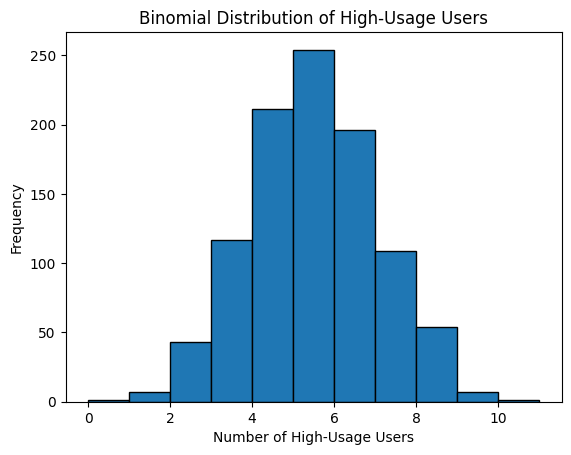

In [ ]:
plt.hist(
    binomial_data,
    bins=range(n + 2),
    edgecolor="black"
)

plt.title("Binomial Distribution of High-Usage Users")
plt.xlabel("Number of High-Usage Users")
plt.ylabel("Frequency")
plt.show()

**Random Sampling**

In [ ]:
sample = df.sample(
    n=10,
    random_state=42
)

display(sample)

,User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
521,U_522,Pinterest,185,18,165,16
737,U_738,Instagram,362,9,138,24
740,U_741,Snapchat,87,3,23,41
660,U_661,Facebook,424,9,97,12
411,U_412,TikTok,403,2,79,29
678,U_679,LinkedIn,127,18,19,24
626,U_627,Twitter,233,18,172,12
513,U_514,Snapchat,156,16,122,34
859,U_860,Snapchat,423,14,116,44
136,U_137,Instagram,145,14,25,17


In [ ]:
sample_without_replacement = df.sample(
    n=10,
    replace=False,
    random_state=42
)

display(sample_without_replacement)

,User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
521,U_522,Pinterest,185,18,165,16
737,U_738,Instagram,362,9,138,24
740,U_741,Snapchat,87,3,23,41
660,U_661,Facebook,424,9,97,12
411,U_412,TikTok,403,2,79,29
678,U_679,LinkedIn,127,18,19,24
626,U_627,Twitter,233,18,172,12
513,U_514,Snapchat,156,16,122,34
859,U_860,Snapchat,423,14,116,44
136,U_137,Instagram,145,14,25,17


In [ ]:
sample_with_replacement = df.sample(
    n=10,
    replace=True,
    random_state=42
)

display(sample_with_replacement)

,User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
102,U_103,Pinterest,413,19,123,9
435,U_436,Instagram,487,20,63,21
860,U_861,Pinterest,53,14,191,25
270,U_271,Snapchat,14,12,11,29
106,U_107,LinkedIn,61,9,41,24
71,U_72,Pinterest,178,18,135,5
700,U_701,Snapchat,251,2,104,17
20,U_21,LinkedIn,52,19,51,33
614,U_615,Instagram,156,10,14,9
121,U_122,Instagram,50,8,168,12


**Population Mean vs Sample Mean**

In [ ]:
population = df["Daily_Minutes_Spent"]

population_mean = population.mean()

sample = population.sample(
    n=10,
    random_state=42
)

sample_mean = sample.mean()

print("Population Mean:", population_mean)
print("Sample Mean:", sample_mean)

Population Mean: 247.368
Sample Mean: 254.5


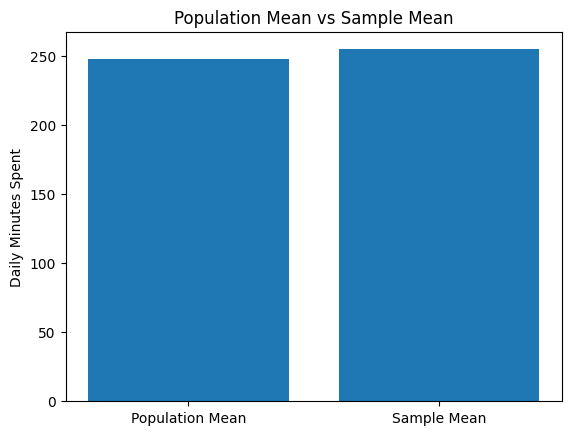

In [ ]:
plt.bar(
    ["Population Mean", "Sample Mean"],
    [population_mean, sample_mean]
)

plt.title("Population Mean vs Sample Mean")
plt.ylabel("Daily Minutes Spent")
plt.show()

**Sampling Distribution of Sample Mean**

In [ ]:
population = df["Daily_Minutes_Spent"].values

sample_size = 10
number_of_samples = 500

sample_means = []

for i in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size,
        replace=True
    )

    sample_means.append(sample.mean())

sample_means = np.array(sample_means)

print("Population Mean:", population.mean())
print("Mean of Sample Means:", sample_means.mean())

Population Mean: 247.368
Mean of Sample Means: 249.61260000000001


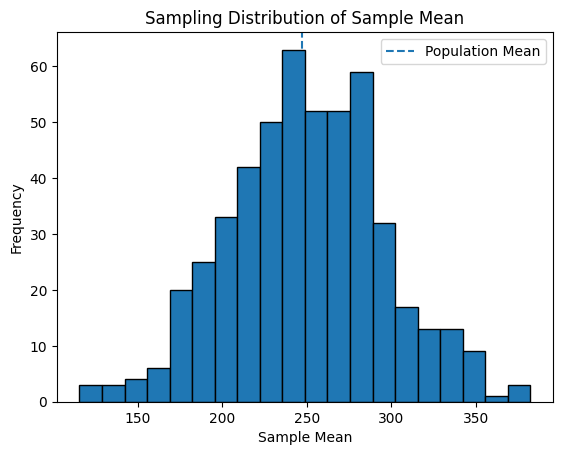

In [ ]:
plt.hist(
    sample_means,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    population.mean(),
    linestyle="--",
    label="Population Mean"
)

plt.title("Sampling Distribution of Sample Mean")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [ ]:
print("Standard Error:", sample_means.std())

Standard Error: 45.80026180318186


**Central Limit Theorem**

In [ ]:
population = df["Daily_Minutes_Spent"].values

sample_size = 30
number_of_samples = 1000

means = []

for i in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size,
        replace=True
    )

    means.append(sample.mean())

means = np.array(means)

print("Population Mean:", population.mean())
print("Mean of Sample Means:", means.mean())

Population Mean: 247.368
Mean of Sample Means: 246.86573333333334


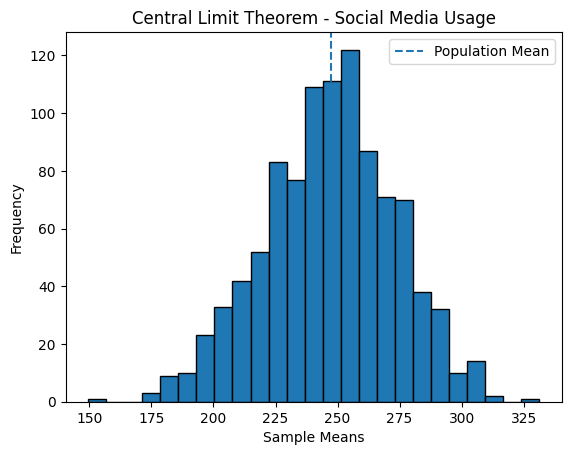

In [ ]:
plt.hist(
    means,
    bins=25,
    edgecolor="black"
)

plt.axvline(
    population.mean(),
    linestyle="--",
    label="Population Mean"
)

plt.title("Central Limit Theorem - Social Media Usage")
plt.xlabel("Sample Means")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [ ]:
print("CLT RESULT")
print("Population Mean:", round(population.mean(), 2))
print("Mean of Sample Means:", round(means.mean(), 2))
print("Standard Deviation:", round(means.std(), 2))

CLT RESULT
Population Mean: 247.37
Mean of Sample Means: 246.87
Standard Deviation: 26.27


Covariance Matrix:
                     Daily_Minutes_Spent  Posts_Per_Day  Likes_Per_Day  \
Daily_Minutes_Spent         21424.739315     -21.476468     114.121145   
Posts_Per_Day                 -21.476468      37.476115       5.952494   
Likes_Per_Day                 114.121145       5.952494    3313.262138   
Follows_Per_Day                81.517654       1.645884     -14.930967   

                     Follows_Per_Day  
Daily_Minutes_Spent        81.517654  
Posts_Per_Day               1.645884  
Likes_Per_Day             -14.930967  
Follows_Per_Day           220.313109  

Pearson Correlation Matrix:
                     Daily_Minutes_Spent  Posts_Per_Day  Likes_Per_Day  \
Daily_Minutes_Spent             1.000000      -0.023968       0.013545   
Posts_Per_Day                  -0.023968       1.000000       0.016892   
Likes_Per_Day                   0.013545       0.016892       1.000000   
Follows_Per_Day                 0.037521       0.018113      -0.017476   

               

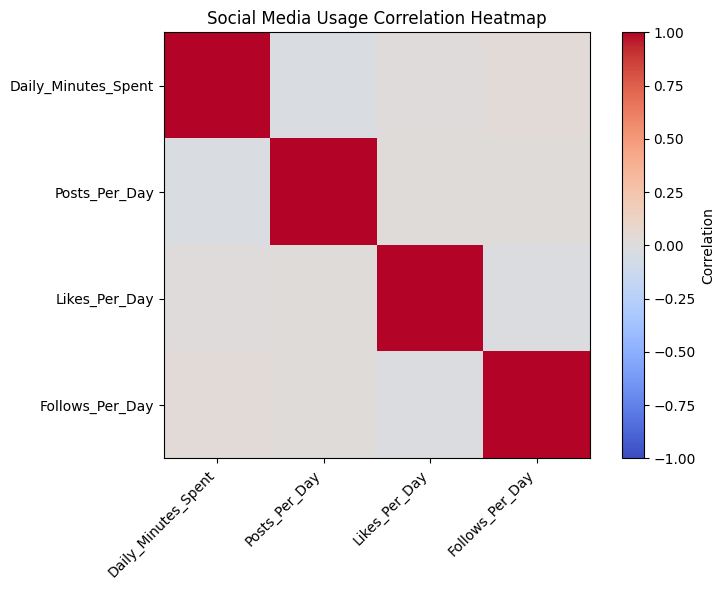

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

numeric_cols = [
    "Daily_Minutes_Spent",
    "Posts_Per_Day",
    "Likes_Per_Day",
    "Follows_Per_Day"
]

# Replaced clean_df with df as defined in previous cells
data = df[numeric_cols].dropna()

# Covariance matrix
print("Covariance Matrix:")
print(data.cov())

# Pearson correlation matrix
print("\nPearson Correlation Matrix:")
print(data.corr(method="pearson"))

# Spearman correlation matrix
print("\nSpearman Correlation Matrix:")
print(data.corr(method="spearman"))

# Correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(data.corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.title("Social Media Usage Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
x = data["Daily_Minutes_Spent"]
y = data["Posts_Per_Day"]

r, p_value = stats.pearsonr(x, y)

print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant linear correlation exists.")
else:
    print("Fail to reject H0: Insufficient evidence of linear correlation.")

Pearson Correlation: -0.023967780205297332
P-value: 0.4489968076097484
Fail to reject H0: Insufficient evidence of linear correlation.


In [ ]:
x = data["Daily_Minutes_Spent"]
mu0 = 240  # Hypothesized mean in minutes

n = len(x)
sample_mean = x.mean()
sample_std = x.std(ddof=1)

z_stat = (sample_mean - mu0) / (sample_std / np.sqrt(n))
p_value = 2 * stats.norm.sf(abs(z_stat))

print("Sample Mean:", sample_mean)
print("Hypothesized Mean:", mu0)
print("Z-statistic:", z_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Mean usage differs significantly from 240 minutes.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Sample Mean: 247.368
Hypothesized Mean: 240
Z-statistic: 1.5918122553393603
P-value: 0.11142689563696115
Fail to reject H0: Insufficient evidence of a difference.


In [ ]:
x = data["Daily_Minutes_Spent"]

t_stat, p_value = stats.ttest_1samp(x, popmean=240)

print("Sample Mean:", x.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Mean usage differs significantly from 240 minutes.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Sample Mean: 247.368
T-statistic: 1.591812255339362
P-value: 0.11174324998712583
Fail to reject H0: Insufficient evidence of a difference.


In [ ]:
app_data = df[["App", "Daily_Minutes_Spent"]].dropna()
apps = app_data["App"].unique()

if len(apps) >= 2:
    group1 = app_data.loc[
        app_data["App"] == apps[0], "Daily_Minutes_Spent"
    ]
    group2 = app_data.loc[
        app_data["App"] == apps[1], "Daily_Minutes_Spent"
    ]

    if len(group1) >= 2 and len(group2) >= 2:
        t_stat, p_value = stats.ttest_ind(
            group1, group2, equal_var=False
        )

        print("App 1:", apps[0], "| Mean:", group1.mean())
        print("App 2:", apps[1], "| Mean:", group2.mean())
        print("Welch T-statistic:", t_stat)
        print("P-value:", p_value)

        if p_value < 0.05:
            print("Significant difference in average daily usage.")
        else:
            print("No statistically significant difference detected.")
    else:
        print("Not enough observations in both groups.")
else:
    print("At least two app categories are required.")

App 1: Pinterest | Mean: 236.20714285714286
App 2: Facebook | Mean: 247.1691176470588
Welch T-statistic: -0.6085946907224029
P-value: 0.5433009443892521
No statistically significant difference detected.


In [ ]:
from scipy.stats import chi2_contingency

# Replaced clean_df with df as defined in previous cells
chi_data = df[["App", "Daily_Minutes_Spent"]].dropna().copy()

median_usage = chi_data["Daily_Minutes_Spent"].median()

chi_data["Usage_Level"] = np.where(
    chi_data["Daily_Minutes_Spent"] > median_usage,
    "High",
    "Low"
)

contingency_table = pd.crosstab(
    chi_data["App"],
    chi_data["Usage_Level"]
)

print("Contingency Table:")
print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("\nChi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: App and usage level are associated.")
else:
    print("Fail to reject H0: No significant association detected.")

print("\nExpected Frequencies:")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
))

Contingency Table:
Usage_Level  High  Low
App                   
Facebook       63   73
Instagram      77   63
LinkedIn       64   83
Pinterest      70   70
Snapchat       87   69
TikTok         61   80
Twitter        76   64

Chi-square Statistic: 10.241018480305682
Degrees of Freedom: 6
P-value: 0.11486230536046796
Fail to reject H0: No significant association detected.

Expected Frequencies:
Usage_Level    High     Low
App                        
Facebook     67.728  68.272
Instagram    69.720  70.280
LinkedIn     73.206  73.794
Pinterest    69.720  70.280
Snapchat     77.688  78.312
TikTok       70.218  70.782
Twitter      69.720  70.280


Intercept: 10.489778542816342
Coefficient: -0.0007791772453895752
R-squared: 0.0007293574123643509
Mean Squared Error: 39.402215726106995


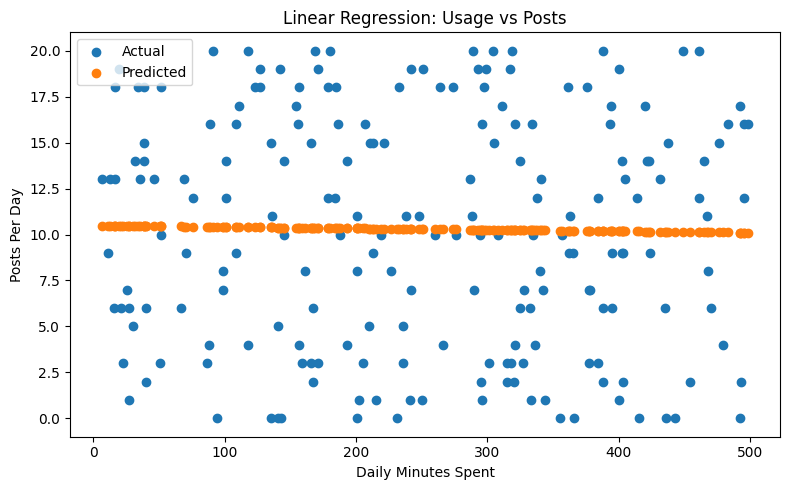

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Corrected variable name from clean_df to df
reg_data = df[
    ["Daily_Minutes_Spent", "Posts_Per_Day"]
].dropna()

X = reg_data[["Daily_Minutes_Spent"]]
y = reg_data["Posts_Per_Day"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("R-squared:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.scatter(X_test["Daily_Minutes_Spent"], y_test, label="Actual")
plt.scatter(X_test["Daily_Minutes_Spent"], y_pred, label="Predicted")
plt.xlabel("Daily Minutes Spent")
plt.ylabel("Posts Per Day")
plt.title("Linear Regression: Usage vs Posts")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# Corrected clean_df to df
log_data = df[
    [
        "Daily_Minutes_Spent",
        "Posts_Per_Day",
        "Likes_Per_Day",
        "Follows_Per_Day"
    ]
].dropna().copy()

median_usage = log_data["Daily_Minutes_Spent"].median()

log_data["High_Usage"] = (
    log_data["Daily_Minutes_Spent"] > median_usage
).astype(int)

X = log_data[
    ["Posts_Per_Day", "Likes_Per_Day", "Follows_Per_Day"]
]
y = log_data["High_Usage"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.48

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.52      0.50       100
           1       0.48      0.44      0.46       100

    accuracy                           0.48       200
   macro avg       0.48      0.48      0.48       200
weighted avg       0.48      0.48      0.48       200

